In [1]:
import numpy as np
import os
from matplotlib import font_manager
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple
font_manager.fontManager.addfont("../../.././arial.ttf")
import numpy as np
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes

plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "pdf.fonttype": 42,
})
plt.rcParams["hatch.linewidth"] = 1

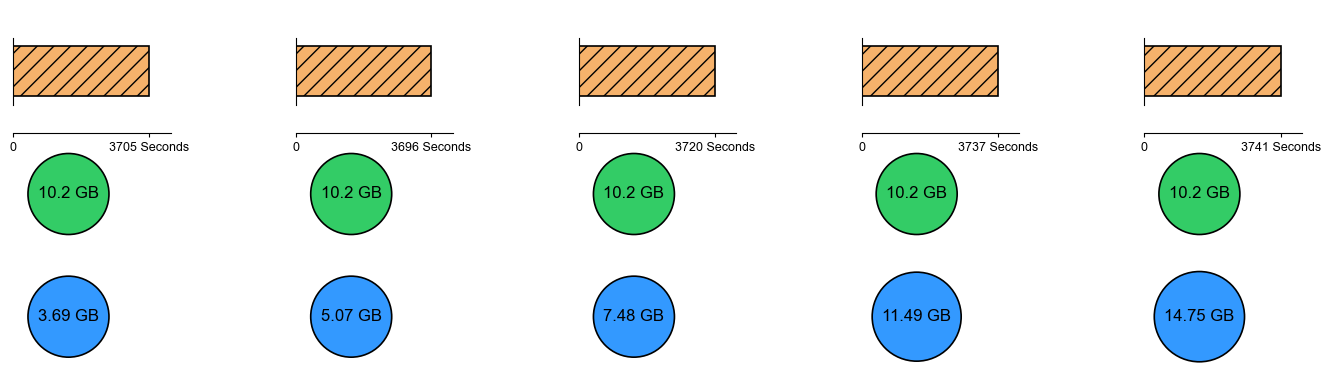

In [2]:
import matplotlib.pyplot as plt

times = [3705, 3696, 3720, 3737, 3741]
time_labels = [f"{t} Seconds" for t in times]

circle_row1 = ["10.2 GB", "10.2 GB", "10.2 GB", "10.2 GB", "10.2 GB"]
circle_row2 = ["3.69 GB", "5.07 GB", "7.48 GB", "11.49 GB", "14.75 GB"]

colors = ["#33CC66", "#3399FF"]

fig, axes = plt.subplots(
    3, 5,
    figsize=(14, 4),
    gridspec_kw={"height_ratios": [1, 1, 1]}
)

for i in range(5):
    # Top row: runtime bars
    ax = axes[0, i]
    ax.barh(
        0, times[i], height=0.45,
        color="#F6B26B", edgecolor="black",
        hatch="//", linewidth=1.2
    )

    ax.set_xlim(0, max(times) * 1.15)
    ax.set_ylim(-0.55, 0.55)
    ax.set_yticks([])
    ax.set_xticks([0, times[i]])
    ax.set_xticklabels(["0", time_labels[i]], fontsize=9)

    ax.spines[["top", "right"]].set_visible(False)
    ax.spines["left"].set_bounds(-0.3, 0.3)
    ax.tick_params(axis="x", length=3)

    # Two rows of circles, shifted left
    for row, labels, color in zip(
        [1, 2], [circle_row1, circle_row2], colors
    ):
        circle_ax = axes[row, i]
        circle_ax.set_axis_off()

        circle_ax.text(
            0.35, 0.5, labels[i],
            transform=circle_ax.transAxes,
            ha="center", va="center", fontsize=12,
            bbox=dict(
                boxstyle="circle,pad=0.6",
                facecolor=color,
                edgecolor="black",
                linewidth=1.2
            )
        )

fig.subplots_adjust(
    left=0.04, right=0.96,
    bottom=0.04, top=0.96,
    hspace=0.0, wspace=0.8
)


plt.show()

In [3]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Run immediately after your plotting loop
fig.subplots_adjust(bottom=0.14)


legend_items = [
    Patch(
        facecolor="#F6B26B", edgecolor="black",
        hatch="//", label="Runtime"
    ),
    Line2D(
        [], [], marker="o", linestyle="None",
        markerfacecolor="#33CC66", markeredgecolor="black",
        markersize=12, label="GPU Peak memory"
    ),
    Line2D(
        [], [], marker="o", linestyle="None",
        markerfacecolor="#3399FF", markeredgecolor="black",
        markersize=12, label="CPU Peak memory"
    )
]

# legend_items = [
#     Patch(facecolor="#F6B26B", edgecolor="black", hatch="//", label="Runtime"),
#     Patch(facecolor="#33CC66", edgecolor="black", label="GPU memory"),
#     Patch(facecolor="#3399FF", edgecolor="black", label="CPU memory")
# ]

fig.legend(
    handles=legend_items,
    loc="lower center",
    bbox_to_anchor=(0.3, 0.01),
    ncol=3,
    frameon=False,
    fontsize=15
)

fig.savefig("runtime_and_memory.pdf", dpi=300)
plt.show()